<a href="https://colab.research.google.com/github/marinazakimi/ECAA08--Grupo-06/blob/main/etapa-03-arvores/%2028_Apresentacao_e_Simulacao_do_Modulo_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 28 — Apresentação e simulação do módulo 3

**ECAA08 — Arquitetura de Sistemas SCADA | Grupo 06**  
**Integrantes:** Arthur, Caique, Luis Felipe e Marina  
**Planta:** Sistema SCADA aplicado a um Drone Agrícola de Pulverização  
**Etapa 3:** Árvores — planejamento e execução supervisionada de missões de pulverização


## 1. Contexto e objetivo no SCADA

Esta aula reúne as nove aplicações de árvores em um demonstrador do Sistema SCADA do Drone Agrícola. O foco é mostrar o fluxo entre planejamento, aquisição simulada, supervisão, histórico e HMI. A entrega inclui um painel de replay em HTML e um painel estático com as variáveis e decisões.

O cenário contém 12 snapshots: espera por aprovação, deslocamento, entrada na faixa, vento alto, recuperação do vento, indício de obstrução, falha retida após parada, inspeção e rearme, indisponibilidade de comunicação, recuperação, solicitação de retorno por bateria baixa e pouso confirmado pelo simulador.

## 2. Modelo e fundamentação

A integração usa os mesmos módulos das aulas anteriores, com responsabilidades distintas:

| Aula | Participação no demonstrador |
|---|---|
| 19 | Referência de conectividade entre base e acessos |
| 20 | Serialização e recuperação dos tipos de eventos gerados |
| 21 | Índice temporal dos registros completos da missão |
| 22 | Caminhos geométricos de ida e retorno |
| 23 | Topologia da LAN antes e depois da falha de enlace |
| 24 | Verificação das transições e marcações da missão |
| 25 | Decisão supervisória reativa a cada snapshot |
| 26 | Consulta do ponto cadastrado mais próximo |
| 27 | Sugestão consultiva de classe operacional |

A árvore de comportamento produz a ação. A rede de Petri verifica a coerência da mudança de fase; ela não substitui a avaliação dos sensores. A saída final da bomba exige todos os permissivos. O historiador registra IDs únicos mesmo quando um alarme e uma ação ocorrem no mesmo instante.

## 3. Procedimento e demonstração

1. Apresentar a arquitetura SCADA e a distinção entre campo, aquisição, servidor e HMI.
2. Mostrar a AGM, o caminho RRT e a aprovação registrada pelo cenário.
3. Executar o replay e acompanhar nível, pressão, vazão, bateria, vento e alarmes.
4. Destacar a pausa por vento e a retenção após indício de obstrução.
5. Mostrar a falha de enlace, o novo STP e a recusa de tratar telemetria vencida como atual.
6. Conferir histórico, transições Petri e ida/volta da codificação.
7. Encerrar com as limitações e a diferença entre simulação e atuação real.

Sugestão para uma apresentação de 12 minutos: 2 min de arquitetura e contexto; 3 min de planejamento e dados; 4 min de replay; 2 min de validação; 1 min de limites.

## 4. Experimentos executáveis

Execute as células em ordem, com a pasta `Arquivos_de_Apoio` ao lado do notebook. Os algoritmos centrais aparecem abaixo; dados, funções comuns e verificações estão nos arquivos de apoio. Não há download de dados durante a execução.

In [ ]:
from pathlib import Path
import sys
# Funciona na pasta da etapa, na raiz do repositório ou em uma subpasta da etapa.
origem = Path.cwd().resolve()
candidatos = [p / sufixo for p in [origem, *origem.parents]
              for sufixo in (Path('.'), Path('etapa-03-arvores'))]
ETAPA = next((p for p in candidatos if (p/'Arquivos_de_Apoio'/'scada_arvores.py').is_file()), None)
if ETAPA is None:
    raise FileNotFoundError('Extraia o pacote completo e abra o notebook na pasta etapa-03-arvores.')
sys.path.insert(0, str(ETAPA/'Arquivos_de_Apoio'))
from scada_arvores import *
import scada_arvores as core
import visualizacao as vis
from verificacoes import TESTES, conferir_rrt
import matplotlib.pyplot as plt
import json
print('Sistema SCADA do Drone Agrícola | Grupo 06 | simulação acadêmica')


Sistema SCADA do Drone Agrícola | Grupo 06 | simulação acadêmica


In [ ]:
def simular_missao(modelo=None):
    """Replay de doze snapshots e confirmações didáticas de fase, sem dinâmica de voo."""
    agm, _ = kruskal(list(PONTOS), arestas_mapa())
    rota = rrt(PONTOS['BASE'], PONTOS['T1'])
    volta = rrt(PONTOS['T1'], PONTOS['BASE'], seed=28)
    assert rota['status'] == volta['status'] == 'SUCESSO'
    if modelo is None: modelo = experimento_classificacao()['modelo']
    nomes = list(PONTOS); kd = kd_construir(list(enumerate(PONTOS.values())))
    rede, marcacao = rede_missao(); alcancaveis = set(atingibilidade(rede, marcacao)[0])
    bb = dict(aprovada=False, rota_ok=True, na_faixa=False)
    cenario = [
        ('Pré-missão: aguarda aprovação', {}, {}),
        ('Aprovação e deslocamento', {'aprovada': True}, {}),
        ('Entrada na faixa confirmada', {'na_faixa': True}, {}),
        ('Vento acima do limite', {}, {'EST_WT_01': 9.}),
        ('Vento normalizado', {}, {}),
        ('Indício de obstrução', {}, {'DRN_PT_01': 5.6, 'DRN_FT_01': .2}),
        ('Bomba parada; falha retida', {}, {'bomba_feedback': False, 'DRN_FT_01': 0.}),
        ('Inspeção e rearme confirmados', {'rearme': True, 'inspecao_confirmada': True}, {}),
        ('Falha do enlace da LAN', {}, {'comm_ok': False, 'idade_s': 3.}),
        ('Rede e telemetria recuperadas', {}, {}),
        ('Bateria baixa: retorno solicitado', {}, {'DRN_ET_01': 15.}),
        ('Pouso confirmado pelo simulador', {'concluida': True}, {'is_flying': False, 'bomba_feedback': False, 'DRN_ET_01': 15.})
    ]
    linhas = []; eventos = []; historico = Historico(); redes = []
    for k, (descricao, mudancas, sensores) in enumerate(cenario):
        bb.update(mudancas); t = telemetria(**sensores)
        links = LINKS if k < 8 else [e for e in LINKS if set(e[:2]) != {'SW_SCADA', 'SW_RADIO'}]
        lan = spanning_tree(links); redes.append(lan)
        # Em k=8 a pausa representa a janela de reconvergência modelada.
        res = tick_supervisor(bb, t); a = res['acao']; estado = LUGARES[marcacao.index(1)]
        transicao = None
        if a == 'DESLOCAR' and estado == 'PRONTA': transicao = 'iniciar'
        elif a == 'PULVERIZAR':
            if estado == 'DESLOCANDO': transicao = 'chegar'
            elif estado == 'PAUSADA': transicao = 'retomar'
        elif a.startswith('PAUSAR') and estado == 'APLICANDO': transicao = 'pausar'
        elif a == 'SOLICITAR_RETORNO':
            assert volta['status'] == 'SUCESSO'
            transicao = {'APLICANDO': 'finalizar_faixas', 'PAUSADA': 'abortar_pausa',
                         'DESLOCANDO': 'abortar_trajeto'}.get(estado)
        elif a == 'CONCLUIR' and estado == 'RETORNANDO': transicao = 'pousar'
        if transicao: marcacao = disparar(marcacao, rede[transicao])
        assert marcacao in alcancaveis and sum(marcacao) == 1
        assert not res['bomba'] or marcacao[2] == 1
        tipo = 0 if a == 'PULVERIZAR' else (3 if a == 'SOLICITAR_RETORNO' else (5 if a == 'CONCLUIR' else 2))
        tipos = ([4] if res['alarmes'] else [])+[tipo]
        for tipo in tipos:
            e = dict(instante_ms=k*1000, id=len(eventos)+1, tipo=tipo, missao='SIM_028', talhao='T1')
            eventos.append(e); historico.inserir(e)
        pos = PONTOS['BASE'] if k < 2 or k == 11 else PONTOS['T1']
        vizinho, _ = kd_vizinho(kd, pos)
        sugestao = CLASSES[prever(modelo, [t[f] for f in FEATURES])] if bb['dados_ok'] else 'INDISPONIVEL'
        linhas.append(dict(tick=k, descricao=descricao, acao=a, estado_petri=LUGARES[marcacao.index(1)],
                           bomba=res['bomba'], alarmes='; '.join(res['alarmes']) or 'SEM_ALARME',
                           sugestao_ml=sugestao, ponto_proximo=nomes[vizinho[0]],
                           pressao=t['DRN_PT_01'], vazao=t['DRN_FT_01'], bateria=t['DRN_ET_01'],
                           nivel=t['DRN_LT_01'], vento=t['EST_WT_01'], transicao=transicao or '—'))
    seq = [e['tipo'] for e in eventos]; pacote = comprimir(seq)
    assert descomprimir(pacote) == seq
    assert historico.percurso() == sorted(eventos, key=lambda e: (e['instante_ms'], e['id']))
    return dict(linhas=linhas, eventos=eventos, agm=agm, rota=rota, volta=volta,
                redes=redes, huffman_bytes=len(pacote), fixo_bytes=len(fixo(seq)))


### Replay de supervisão e histórico

In [ ]:
modelo=experimento_classificacao()['modelo']
sim=simular_missao(modelo)
for r in sim['linhas']:
    print(f"{r['tick']:02d} | {r['acao']:20} | bomba={int(r['bomba'])} | {r['estado_petri']:11} | {r['alarmes']}")
print('Eventos:',len(sim['eventos']))
print('Bytes fixo / Huffman:',sim['fixo_bytes'],sim['huffman_bytes'])
assert sim['linhas'][-1]['estado_petri']=='CONCLUIDA'

00 | AGUARDAR_OPERADOR    | bomba=0 | PRONTA      | SEM_ALARME
01 | DESLOCAR             | bomba=0 | DESLOCANDO  | SEM_ALARME
02 | PULVERIZAR           | bomba=1 | APLICANDO   | SEM_ALARME
03 | PAUSAR               | bomba=0 | PAUSADA     | VENTO_ALTO
04 | PULVERIZAR           | bomba=1 | APLICANDO   | SEM_ALARME
05 | PAUSAR               | bomba=0 | PAUSADA     | FALHA_PULVERIZACAO; POSSIVEL_OBSTRUCAO; FALHA_RETIDA
06 | PAUSAR               | bomba=0 | PAUSADA     | FALHA_RETIDA
07 | PULVERIZAR           | bomba=1 | APLICANDO   | SEM_ALARME
08 | PAUSAR_DADOS         | bomba=0 | PAUSADA     | TELEMETRIA_INDISPONIVEL
09 | PULVERIZAR           | bomba=1 | APLICANDO   | SEM_ALARME
10 | SOLICITAR_RETORNO    | bomba=0 | RETORNANDO  | SEM_ALARME
11 | CONCLUIR             | bomba=0 | CONCLUIDA   | SEM_ALARME
Eventos: 16
Bytes fixo / Huffman: 16 35


### Painel HMI e comparação antes/depois da falha

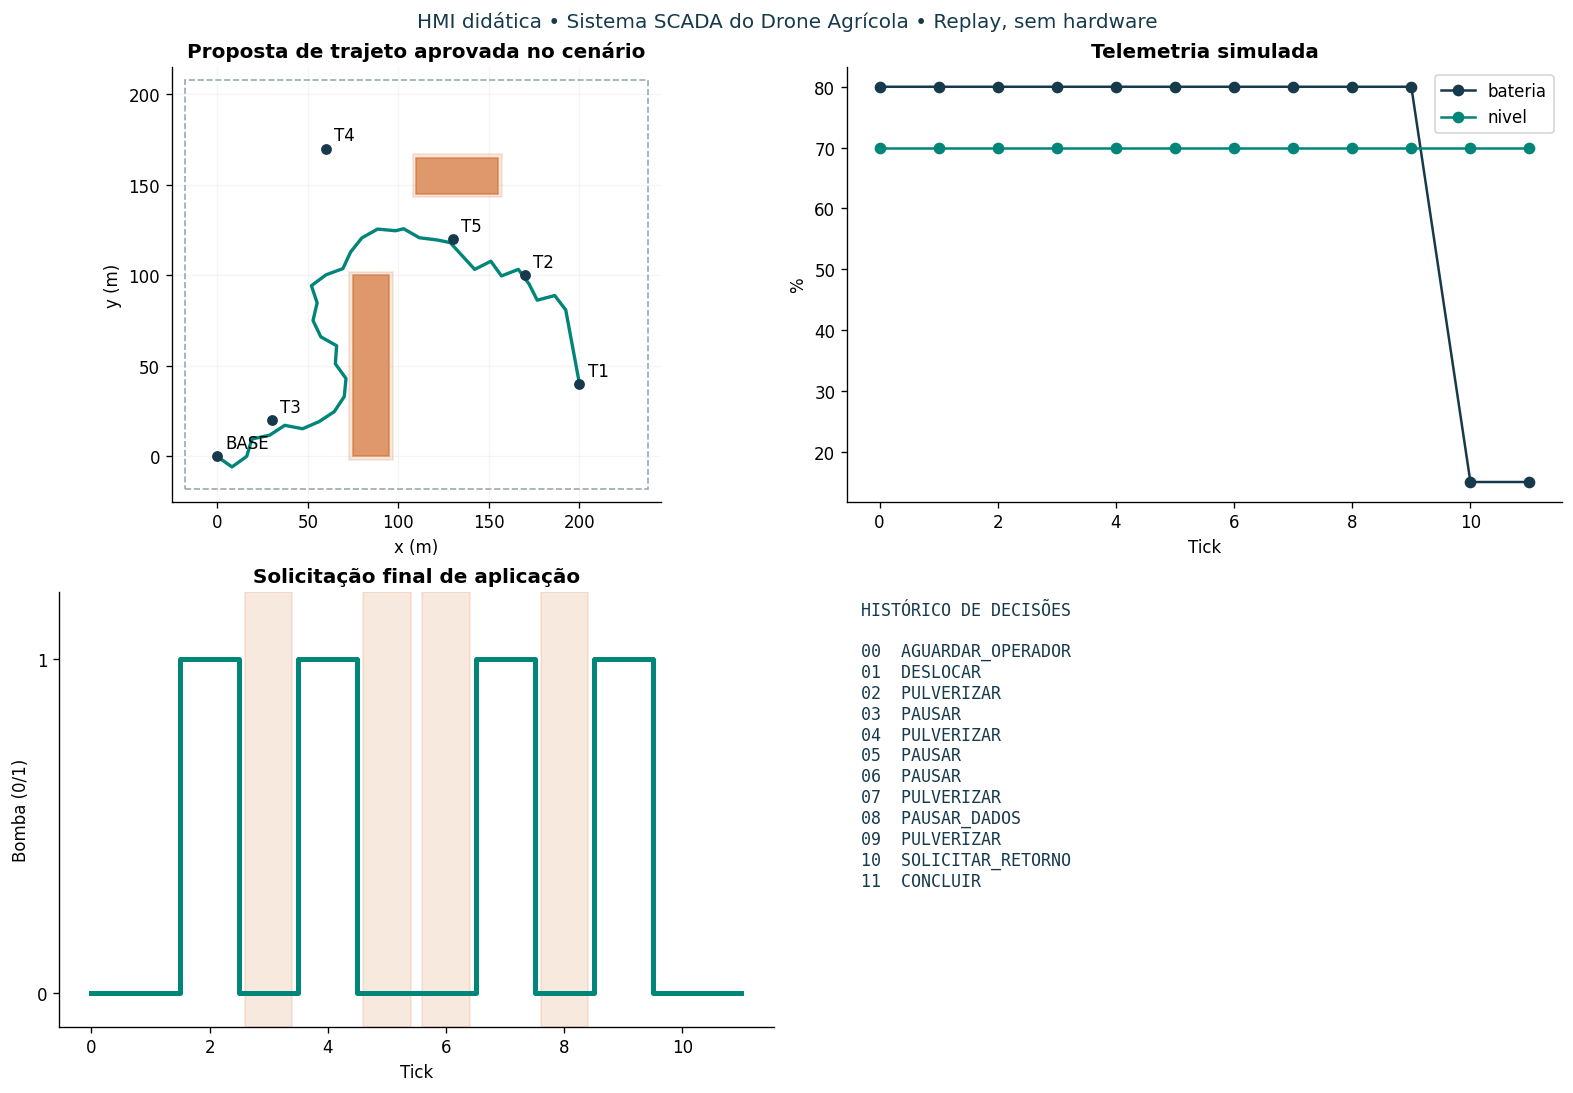

LAN inicial: [('SW_SCADA', 'SW_HMI', 10), ('SW_SCADA', 'SW_RADIO', 10)]
LAN após falha: [('SW_SCADA', 'SW_HMI', 10), ('SW_HMI', 'SW_RADIO', 1)]
Estado do tick de comunicação: {'tick': 8, 'descricao': 'Falha do enlace da LAN', 'acao': 'PAUSAR_DADOS', 'estado_petri': 'PAUSADA', 'bomba': False, 'alarmes': 'TELEMETRIA_INDISPONIVEL', 'sugestao_ml': 'INDISPONIVEL', 'ponto_proximo': 'T1', 'pressao': 3.0, 'vazao': 2.0, 'bateria': 80.0, 'nivel': 70.0, 'vento': 3.0, 'transicao': 'pausar'}
Sugestões ML: [(0, 'NORMAL'), (1, 'NORMAL'), (2, 'NORMAL'), (3, 'VENTO_ALTO'), (4, 'NORMAL'), (5, 'OBSTRUCAO'), (6, 'OBSTRUCAO'), (7, 'NORMAL'), (8, 'INDISPONIVEL'), (9, 'NORMAL'), (10, 'BATERIA_BAIXA'), (11, 'BATERIA_BAIXA')]


In [ ]:
vis.figura28(sim);plt.show()
print('LAN inicial:',sim['redes'][0]['ativas'])
print('LAN após falha:',sim['redes'][8]['ativas'])
print('Estado do tick de comunicação:',sim['linhas'][8])
print('Sugestões ML:',[(r['tick'],r['sugestao_ml']) for r in sim['linhas']])

### Verificação e resultados de referência

As verificações confrontam propriedades, referências independentes e casos de fronteira. Consulte `Arquivos_de_Apoio/verificacoes.py` para os critérios completos.

In [ ]:
RESUMO = TESTES[28]()
print(json.dumps(RESUMO, ensure_ascii=False, indent=2))
print('Verificações da aula 28: APROVADAS')

{
  "ticks": 12,
  "eventos": 16,
  "estado_final": "CONCLUIDA",
  "pacote_huffman_bytes": 35,
  "pacote_fixo_bytes": 16
}
Verificações da aula 28: APROVADAS


## 5. Interpretação, limites e continuidade

Os instantes são índices de snapshots, sem relação com tempo de voo. O simulador confirma entrada na faixa e pouso; não integra posição, dinâmica, consumo ou cobertura agrícola. Bateria e nível são leituras fictícias, não resultados de um modelo de autonomia. A recuperação da LAN é um evento de cenário, não uma medição de RSTP.

O painel HTML reproduz resultados calculados; seus controles navegam no histórico e não enviam comandos. Não há conexão com rádio, Elipse, RTU física ou actuadores. O projeto continua sendo um SCADA em desenvolvimento por etapas: as funções implementadas aqui são módulos didáticos integrados de supervisão. As Etapas 1 e 2 permanecem como entregues.

Todos os arquivos usam caminhos relativos. No GitHub, leia o README, os documentos e as imagens; para executar o painel HTML, baixe a pasta e abra o arquivo localmente. Para recalcular os resultados, execute o notebook ou o validador.

## 6. Referências

- [README da Etapa 3](README.md).
- [Continuidade e hipóteses](Arquivos_de_Apoio/Continuidade_e_Hipoteses.md).
- [Relatório de validação](Arquivos_de_Apoio/Relatorio_de_Validacao.md).